# Representative episode timelines

Qwen3.5-9B · SWE-bench Pro V2 · native AgentENV.
Based on the lifecycle figure in `flash-sandbox/meta/plot/3_paper/1_characterization.ipynb`:
stacked concurrency panels, four episode lanes each, matching fonts and phase colors.
A **9 × 5.5-inch** canvas leaves room for 12 episode lanes and readable labels.

For each concurrency (128, 256, 512), select the **four episodes nearest the
median sandbox lifetime** among fully paired, complete, error-free-call traces with
at least two model calls and a clear final shell-close boundary. This conditional
cohort excludes API errors, including timeout-heavy episodes; it does not represent
all attempts or prove reward verification succeeded. The 512 run had an engine failure;
its four lanes are selected from only **173 eligible error-free-call episodes**, not
from the failing episodes. Episodes are not matched by task across concurrency levels.

Every lane independently starts at sandbox creation invocation and ends at sandbox
stop invocation (deletion time is excluded). `e1`–`e4` are display IDs, sorted by lifetime within each panel.
The table below records their real sandbox IDs and source trace filenames.

In [10]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATA = PLOT / 'data/episode_timelines_20261015.json'
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_1': '#DDF3DE', 'green_2': '#AADCA9', 'green_3': '#8BCF8B',
    'red_1': '#F6CFCB', 'red_2': '#E9A6A1', 'red_strong': '#B64342',
    'neutral': '#CFCECE', 'highlight': '#FFD700',
    'teal': '#42949E', 'violet': '#9A4D8E',
}

In [11]:
EXPECTED_SHA256 = '5a7e589c61d3fa9d6715dcd94ff08c8d8b0cf308ebfc6d1302867f443eef05e5'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == EXPECTED_SHA256
timelines = json.loads(DATA.read_text())
assert [p['episode_ceiling'] for p in timelines['points']] == [128, 256, 512]
rows = []
for point in timelines['points']:
    assert len(point['episodes']) == 4
    for index, episode in enumerate(point['episodes'], 1):
        segments = episode['segments']
        assert segments[0]['start_s'] == 0
        assert np.isclose(segments[-1]['end_s'], episode['lifetime_s'])
        assert all(s['end_s'] > s['start_s'] for s in segments)
        assert all(np.isclose(a['end_s'], b['start_s'])
                   for a, b in zip(segments, segments[1:]))
        assert np.isclose(sum(episode['phase_seconds'].values()), episode['lifetime_s'])
        rows.append({
            'concurrent_trajectories': point['episode_ceiling'], 'lane': f'e{index}',
            'sandbox_id': episode['sandbox_id'], 'trace_file': episode['trace_file'],
            'lifetime_s': episode['lifetime_s'], 'model_calls': episode['model_calls'],
            'eligible_episodes': point['eligible_episodes'],
            'eligible_median_s': point['eligible_median_lifetime_s'],
            **episode['phase_seconds'],
        })
selection = pd.DataFrame(rows)
display(selection.round(2))
selection.to_csv(FIGURES / 'episode_timelines_pro_selection.csv', index=False)
# Startup statistics over all successful start calls, not just selected episodes.
startup_summary = pd.DataFrame([{
    'concurrent_trajectories': p['episode_ceiling'],
    'successful_starts': p['successful_start_calls'],
    'median_cold_start_s': p['successful_start_median_s'],
    'p90_cold_start_s': p['successful_start_p90_s'],
} for p in timelines['points']])
display(startup_summary.round(2))
startup_summary.to_csv(FIGURES / 'episode_timelines_pro_cold_start_summary.csv', index=False)


,concurrent_trajectories,lane,sandbox_id,trace_file,lifetime_s,model_calls,eligible_episodes,eligible_median_s,Cold Start,LLM Wait,Sandbox Interaction,Setup,Verification
0,128,e1,01a14144-2d84-7a03-9534-6d0f48fde025,2af832ab92cf46ce9d7e843bbaa998da.jsonl,84.13,6,759,84.19,2.28,4.59,2.81,0.92,73.53
1,128,e2,01a14142-fb0d-7ab3-8bbd-578f2cbd977e,4fbe39d2e542442b98922ac842aa4498.jsonl,84.19,4,759,84.19,2.56,3.04,1.97,0.91,75.70
2,128,e3,01a14140-87e9-75a0-992e-fdfe4c95bb27,8561f974481f4e7cbf623de6f072f278.jsonl,84.24,6,759,84.19,2.12,4.79,2.86,0.96,73.51
3,128,e4,01a14144-2d56-7aa2-aaff-2de80101ea86,3ab155384b5841feb64ed4368e02872a.jsonl,84.57,6,759,84.19,2.32,5.29,2.92,0.91,73.13
4,256,e1,01a1415d-028d-7b12-881e-35fe500c002a,dda076014e944bbc95a17902b73a3f93.jsonl,104.00,9,508,104.04,4.57,9.46,4.99,1.04,83.95
5,256,e2,01a1415e-00f4-7dd0-b595-4938dbd9f200,d8a62fc914394e908e9f61b3fa070cb8.jsonl,104.08,4,508,104.04,4.98,3.65,2.75,1.06,91.64
6,256,e3,01a14160-3aec-7310-a729-ffa036d38a73,cb756d56b8d4479b98a116ab0e5075a2.jsonl,104.32,8,508,104.04,4.68,14.60,4.10,1.07,79.87
7,256,e4,01a14157-069b-78f2-bcc6-8f590000460a,7df390dc64b74433a636a5358cd5d4f1.jsonl,104.53,8,508,104.04,11.27,36.65,7.18,0.91,48.52
8,512,e1,01a1416c-e458-7cb2-b507-26c86048701f,3457410b4ea94de2abfb9fdde0597a20.jsonl,140.55,4,173,146.84,15.73,18.01,1.84,0.87,104.11
9,512,e2,01a1416c-dc9a-7d83-b418-22b33fc313a2,00625fb1c2db4285815b6d3e3c7f3293.jsonl,146.84,4,173,146.84,18.05,19.90,1.93,0.86,106.10


,concurrent_trajectories,successful_starts,median_cold_start_s,p90_cold_start_s
0,128,1021,2.68,3.91
1,256,1020,4.90,12.48
2,512,1024,11.47,25.65


**Original timeline phase conventions**

The five legend labels and colors match the reference: **LLM Wait**, **Cold Start**,
**Setup**, **Sandbox Interaction**, and **Verification**.

- **Cold Start:** measured native start interval, including readiness checks.
- **Setup:** startup completion through the first model call, including workdir and shell setup.
- **Sandbox Interaction:** measured native operations during the agent interaction phase.
- **Verification:** an inferred phase from final agent shell-close completion to sandbox stop
  invocation. This includes patch handling and artifact overhead as well as verifier work;
  exported traces do not provide finer verifier boundaries or establish evaluation success.
- **LLM Wait:** residual time during agent execution after subtracting measured sandbox calls,
  following the original's residual-time convention. It includes model calls and untraced
  orchestration gaps; it is not a direct measure of model-compute time.

Every lane is partitioned without overlap, from start invocation to stop invocation;
stop/deletion duration is excluded. Short operations retain their true widths.

**Run context**

Across all successful start calls, median startup is **2.68 s at 128**, **4.90 s at 256**,
and **11.47 s at 512**. These points followed the initial 64-concurrency run in a
single ordered sweep, so image-cache history and concurrency are confounded.
The 512 point encountered a vLLM engine failure; the timelines show its surviving
error-free-call cohort and do not characterize the failed trajectories.


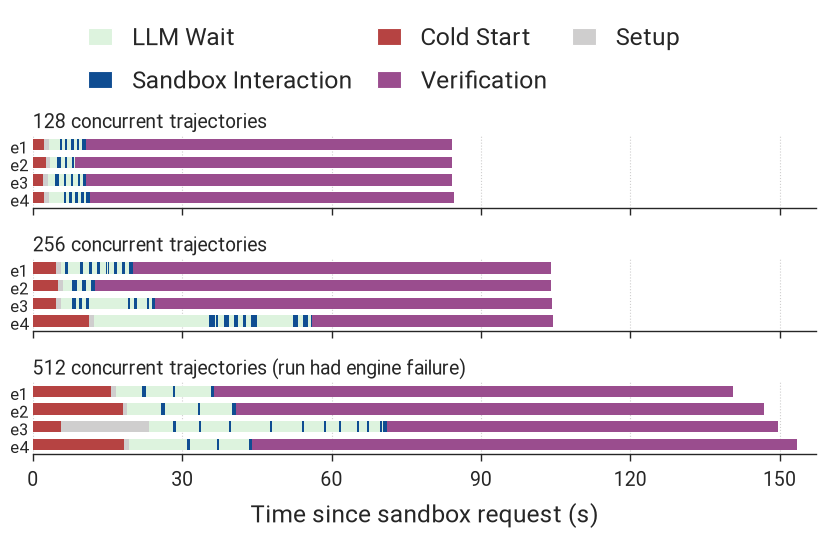

In [ ]:
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

PHASE_COLORS = {
    'LLM Wait': PALETTE['green_1'],
    'Cold Start': PALETTE['red_strong'],
    'Setup': PALETTE['neutral'],
    'Sandbox Interaction': PALETTE['blue_main'],
    'Verification': PALETTE['violet'],
}
fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True)
fig.subplots_adjust(left=.11, right=.98, bottom=.17, top=.75, hspace=.70)
xmax = max(e['lifetime_s'] for p in timelines['points'] for e in p['episodes']) * 1.025
for ax, point in zip(axes, timelines['points']):
    for index, episode in enumerate(point['episodes']):
        y = 3 - index
        for phase, color in PHASE_COLORS.items():
            intervals = [(s['start_s'], s['end_s'] - s['start_s'])
                         for s in episode['segments'] if s['category'] == phase]
            if intervals:
                ax.broken_barh(intervals, (y - .32, .64),
                               facecolors=color, edgecolors='none')
    ax.set(xlim=(0, xmax), ylim=(-.55, 3.55),
           yticks=[0, 1, 2, 3], yticklabels=['e4', 'e3', 'e2', 'e1'])
    suffix = " (run had engine failure)" if point['episode_ceiling'] == 512 else ""
    ax.set_title(f"{point['episode_ceiling']} concurrent trajectories{suffix}",
                 loc='left', fontsize=14, pad=5)
    ax.tick_params(axis='y', labelsize=12, length=0)
    ax.tick_params(axis='x', labelsize=14)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.set_axisbelow(True)
    ax.grid(axis='x', linestyle=':', color=PALETTE['neutral'])
    sns.despine(ax=ax, left=True)
axes[-1].set_xlabel('Time since sandbox request (s)', fontsize=17.6)
handles = [Patch(facecolor=color, label=phase) for phase, color in PHASE_COLORS.items()]
# Matplotlib fills columns first: reorder so the legend reads across rows.
fig.legend(handles=[handles[i] for i in (0, 3, 1, 4, 2)],
           loc='upper center', bbox_to_anchor=(.5, 1.0), ncol=3,
           fontsize=17.6, frameon=False, handlelength=1.0,
           columnspacing=1.0, labelspacing=.45)
for extension in ('pdf', 'png', 'svg'):
    fig.savefig(FIGURES / f'episode_timelines_pro.{extension}', dpi=300,
                facecolor='white')
display(fig)
plt.close(fig)

The frozen JSON includes source SHA-256 hashes, eligibility/exclusion counts,
selection policy, measured phase intervals, and original sandbox identifiers.
Re-extract from the local campaign exports with:

```bash
python meta/plot/extract_episode_timelines.py
```

After deliberate re-extraction, update the expected JSON hash in this notebook.
Plotting needs only the frozen JSON, not the ignored `outputs/` directory.
Exports: `figure/episode_timelines_pro.{pdf,png,svg}` and
`figure/episode_timeline_selection.csv`.